# CUTI v4: CUTI and CROCO $W_{MLD}$ on the native grid (5–16°S)

Per row $j$ of the native 1/12° grid, the 12 boxes nearest the coast ($A_j$, ≈109 km), per metre of coastline $L_j$:

$$U^{Ek}_j=\frac{1}{L_j}\iint_{A_j}\nabla\cdot\mathbf U_{ek}\,dA,\qquad
U^{Geo}_j=\frac{1}{L_j}\iint_{A_j}\Big(\frac{\partial u_g}{\partial x}+\frac{\partial v_g}{\partial y}\Big)\,\mathrm{MLD}\,dA,\qquad
\mathrm{CUTI}_j=U^{Ek}_j+U^{Geo}_j,\qquad W_j=\frac{1}{L_j}\iint_{A_j}W_{MLD}\,dA$$

* **Ekman:** ERA5 forcing winds on the native C-grid, $\tau=\rho_a C_d|\mathbf U|\mathbf U$, $U_{ek}=\tau_y/(\rho_0 f)$, $V_{ek}=-\tau_x/(\rho_0 f)$.
* **Geostrophy:** $u_g=-\frac{g}{f}\partial_y\mathrm{SSH}$, $v_g=\frac{g}{f}\partial_x\mathrm{SSH}$; MLD multiplies the divergence (Eq. 2.7), which is $w$ at $z=-\mathrm{MLD}$, the quantity CROCO's $W_{MLD}$ measures.
* **Closed box:** no flux through any ocean–land face, for Ekman and geostrophic flow.
* **Grid:** face lengths and cell areas from CROCO `pm`, `pn` (Mercator grid, row height varies with latitude).
* **Regions and bins:** $(1/L)\iint$ over all rows, i.e. total transport / total coast length.

Output: `CUTI_BEUTI_HR_L_v4.nc`.

## 1. Setup

In [52]:
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt

R      = 6371000.0        # Earth radius, m (distances along the coast and plots)
Omega  = 7.2921e-5        # rotation rate, s-1 (geostrophy)
g      = 9.81             # m s-2
DEG2M  = R * np.deg2rad(1.0)

# Ekman transport: paper bulk formula, tau = rho_air Cd |U| U, U_ek = tau_y/(rho_sw f), V_ek = -tau_x/(rho_sw f)
RHO_AIR, CD, RHO_SW, OMEGA_EK = 1.22, 1.3e-3, 1025.0, 7.29e-5
WIND_FILES = '/gxfs_work/geomar/smomw662/NHCS/Winds_input/hindcast_1980_2015/INPUT/mean_croco_blk_ERA5_Y{y}M{m}.nc'
GRID_FILE  = '/gxfs_work/geomar/smomw662/NHCS/hincast_1980-2015/croco_avg_Y1980M01.nc'   # pm, pn, mask_rho
YEARS      = range(1980, 2016)

lati2, lati1  = -17, -4   # domain (south, north); bins start at lati1 and go south
mask_km       = 109       # band: round(mask_km / dx) = 12 boxes per row, coast box included

# None = one value per grid row (no binning)
resolutions = {'row (1/12°)': None, '0.25°': 0.25, '0.5°': 0.5, '1°': 1.0}

bs = dict(lat_band=slice(-16, -5))   # analysis range, 5S-16S (lat_band ascending here)
N_BOOT = 200                         # bootstrap replicates for the confidence intervals

In [53]:
def haversine(lat1, lon1, lat2, lon2):
    lat1_rad, lon1_rad = np.deg2rad(lat1), np.deg2rad(lon1)
    lat2_rad, lon2_rad = np.deg2rad(lat2), np.deg2rad(lon2)
    a = (np.sin((lat2_rad - lat1_rad) / 2.0) ** 2
         + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin((lon2_rad - lon1_rad) / 2.0) ** 2)
    return R * 2 * np.arcsin(np.sqrt(a))


def coastal_band_mask(ocean, dx, target_width_km=109):
    """Coastal band: round(width/dx) boxes per row, coast box included.
    Coast = easternmost ocean cell of the row (from the ocean mask). Returns (band, coast index per row, -1 = none)."""
    oc = ocean.values.astype(bool)
    band = np.zeros_like(oc)
    i_coast = np.full(oc.shape[0], -1)
    for j in range(oc.shape[0]):
        cols = np.where(oc[j])[0]
        if len(cols) == 0:
            continue
        i_coast[j] = cols[-1]
        n_cells = int(np.round(target_width_km * 1e3 / float(dx[j])))
        band[j, max(i_coast[j] - n_cells + 1, 0):i_coast[j] + 1] = True
    band = xr.DataArray(band & oc, dims=('lat', 'lon'), coords={'lat': ocean.lat, 'lon': ocean.lon})
    return band, xr.DataArray(i_coast, dims='lat', coords={'lat': ocean.lat})


def band_lons(mask_band, i_coast):
    """Coast (easternmost ocean cell, from the coast index) and offshore (westernmost band cell) longitude per row."""
    lon = mask_band.lon.values
    coast = xr.DataArray(np.where(i_coast >= 0, lon[np.maximum(i_coast.values, 0)], np.nan), dims='lat', coords={'lat': mask_band.lat})
    return coast, mask_band.lon.where(mask_band).min('lon')


def coast_row_lengths(lats, coast_lons):
    """Along-coast length (m) attributed to each grid row: half the distance to each
    neighbouring coast cell (full distance at the two ends). Rows without coast -> NaN."""
    lats, lon = np.asarray(lats, float), np.asarray(coast_lons, float)
    ok = np.isfinite(lon)
    la, lo = lats[ok], lon[ok]
    d  = haversine(la[:-1], lo[:-1], la[1:], lo[1:])
    ds = np.empty(len(la))
    ds[1:-1] = 0.5 * (d[:-1] + d[1:])
    ds[0], ds[-1] = d[0], d[-1]
    out = np.full(len(lats), np.nan)
    out[ok] = ds
    return xr.DataArray(out, dims='lat', coords={'lat': lats}, name='ds')


def bin_centers(lat, dbin):
    """Centre of the half-open bin [edge - dbin, edge) each latitude falls in, edges from lati1 southward."""
    k = np.floor((lati1 - np.asarray(lat)) / dbin + 1e-9).astype(int)
    return np.round(lati1 - (k + 0.5) * dbin, 6)


def bin_rows(da, dbin, how='sum'):
    """Aggregate a (.., lat) row field into latitude bins of width dbin -> dim lat_band.
    dbin=None returns the rows themselves, renamed to lat_band."""
    if dbin is None:
        return da.rename(lat='lat_band')
    da = da.assign_coords(lat_band=('lat', bin_centers(da.lat.values, dbin)))
    grp = da.groupby('lat_band')
    return grp.sum('lat', min_count=1) if how == 'sum' else grp.mean('lat')


def coast_mean(x, dbin=None):
    """Region value as in Eq. 2.7, (1/L) iint over all rows: sum_j X_j L_j / sum_j L_j for X_j per metre of coast
    (= total transport / total coast length). x: (.., lat_band) at resolution dbin; returns (..)."""
    Lb = bin_rows(ds_ok, dbin).sortby('lat_band').reindex(lat_band=x.lat_band, method='nearest', tolerance=1e-6)
    w = Lb.where(x.notnull())
    return (x * w).sum('lat_band') / w.sum('lat_band')


def seasonality(data):
    return data.groupby('time.month').mean(dim='time')


# ---------------- statistics (Fisher z, anomalies, effective sample size, block bootstrap)
def fisher_mean(r):
    r = np.asarray(r, float)
    return float(np.tanh(np.nanmean(np.arctanh(np.clip(r, -0.999999, 0.999999)))))


def anomalies(x):
    return x.groupby('time.month') - x.groupby('time.month').mean('time')


def lag1(x, dim):
    x = x - x.mean(dim)
    return float((x * x.shift({dim: 1})).sum() / (x * x).sum())


def n_eff(a, b, dim):
    """Bretherton et al. (1999): n (1 - r1 r2)/(1 + r1 r2) from the lag-1 autocorrelations."""
    r1, r2 = lag1(a, dim), lag1(b, dim)
    return a.sizes[dim] * (1 - r1 * r2) / (1 + r1 * r2)


def boot_time(C, W, years, n=N_BOOT, seed=0):
    """95 % CI of the Fisher-mean r(time) over lat_band, resampling whole years."""
    rng = np.random.default_rng(seed)
    yrs = np.unique(years)
    idx_y = {y: np.where(years == y)[0] for y in yrs}
    out = []
    for _ in range(n):
        idx = np.concatenate([idx_y[y] for y in rng.choice(yrs, len(yrs))])
        out.append(fisher_mean(xr.corr(C.isel(time=idx), W.isel(time=idx), dim='time').values))
    return np.percentile(out, [2.5, 97.5])


def boot_profile(Cp, Wp, block, n=1000, seed=0):
    """95 % CI of r(profile), moving-block bootstrap along lat_band (block = number of bins)."""
    rng = np.random.default_rng(seed)
    a, b = Cp.values, Wp.values
    m = len(a); block = max(1, min(block, m))
    out = []
    for _ in range(n):
        st = rng.integers(0, m - block + 1, int(np.ceil(m / block)))
        idx = np.concatenate([np.arange(s, s + block) for s in st])[:m]
        out.append(np.corrcoef(a[idx], b[idx])[0, 1])
    return np.nanpercentile(out, [2.5, 97.5])

## 2. SSH, MLD, model grid, coastal band and coast length per row

Land mask from MLD (`SSH.nc` stores 0.0 over land). Coast = easternmost ocean cell of each row; $L_j$ = half the distance to the coast point of each neighbouring row.

In [54]:
# padded by 2 degrees N/S: face fluxes use shifted neighbours
reg2d = dict(lon=slice(-85, None), lat=slice(lati2 - 2, lati1 + 2))
rows  = dict(lat=slice(lati2, lati1))          # rows that enter the CUTI

# --- MLD first: it carries the land mask (SSH.nc fills land with 0.0, not NaN) ---
mld_all = xr.open_dataset('MLD.nc')
assert (np.diff(mld_all.lat.values) > 0).all(), 'latitude must be ascending (shifts below assume it)'
mld_ds = mld_all.sel(**reg2d).compute()
ocean  = np.isfinite(mld_ds.MLD.isel(time=0)).drop_vars('time')

ssh_ds = xr.open_dataset('SSH.nc').sel(**reg2d).compute().astype('float64')
assert np.array_equal(ssh_ds.lat.values, ocean.lat.values) and np.array_equal(ssh_ds.lon.values, ocean.lon.values)
eta    = ssh_ds.SSH.where(ocean)

# --- CROCO grid metrics (rho points of the same grid; pm = 1/dx, pn = 1/dy) ---
grd = xr.open_dataset(GRID_FILE, decode_times=False)[['pm', 'pn', 'mask_rho']]
grd = grd.rename(eta_rho='lat', xi_rho='lon').assign_coords(lat=mld_all.lat.values, lon=mld_all.lon.values).sel(**reg2d).load()
assert ((grd.mask_rho > 0) == ocean).all(), 'CROCO mask_rho and MLD land mask differ'
pm, pn = grd.pm, grd.pn
dA   = 1.0 / (pm * pn)                                        # cell area, m2
dy_e = 2.0 / (pn + pn.shift(lon=-1))                          # length of the EAST face of each cell, m
dx_n = 2.0 / (pm + pm.shift(lat=-1))                          # length of the NORTH face of each cell, m
lat_n = xr.DataArray(0.5 * (eta.lat.values + np.r_[eta.lat.values[1:], np.nan]), dims='lat', coords={'lat': eta.lat})  # north-face latitude
open_e = ocean & ocean.shift(lon=-1, fill_value=False)        # east face between two ocean cells
open_n = ocean & ocean.shift(lat=-1, fill_value=False)        # north face between two ocean cells
dx_row = (1.0 / pm).mean('lon')                               # dx of each row, m

mask_band, i_coast = coastal_band_mask(ocean, dx_row, target_width_km=mask_km)
lat_all   = eta.lat.values
coast_lons, _ = band_lons(mask_band, i_coast)

mld_raw = mld_ds.MLD.astype('float64')
mld     = mld_raw.where(mask_band)
del ssh_ds, mld_ds

ds_row = coast_row_lengths(lat_all, coast_lons.values)
print('grid dlat [deg]: min %.4f, max %.4f (Mercator)' % (np.diff(lat_all).min(), np.diff(lat_all).max()))
print('ds per row [km]: median %.1f, max %.1f (rows > 2x median: %d)'
      % (float(ds_row.sel(**rows).median()) / 1e3, float(ds_row.sel(**rows).max()) / 1e3,
         int((ds_row.sel(**rows) > 2 * ds_row.sel(**rows).median()).sum())))

grid dlat [deg]: min 0.0788, max 0.0833 (Mercator)
ds per row [km]: median 11.1, max 28.2 (rows > 2x median: 4)


## 3. $U^{Geo}$ per row (Eq. 2.7)

* $u_g$, $v_g$ at cell centres from centred SSH differences on the CROCO metrics; across a land neighbour the gradient is 0 (no coast-parallel geostrophic velocity in that direction).
* Face flux per unit depth = mean of the two neighbouring velocities × face length; every ocean–land face is closed.
* $\iint_{A_j}(\partial_x u_g+\partial_y v_g)\,\mathrm{MLD}\,dA=\sum_{i\in A_j}\mathrm{MLD}_i\,(\nabla\cdot\mathbf u_g)_i\,A_i$.

In [55]:
def centred_gradient(P, dim):
    # dP/d(dim) at cell centres on the CROCO metrics; 0 where a neighbour in that direction is land
    if dim == 'lon':
        d_p, op_p = 2.0 / (pm + pm.shift(lon=-1)), open_e      # distance to / open face with the east neighbour
    else:
        d_p, op_p = 2.0 / (pn + pn.shift(lat=-1)), open_n      # ... north neighbour
    d_m, op_m = d_p.shift({dim: 1}), op_p.shift({dim: 1}, fill_value=False)
    dP_p = (P.shift({dim: -1}) - P).where(op_p, 0.0)
    dP_m = (P - P.shift({dim: 1})).where(op_m, 0.0)
    grad = ((dP_p + dP_m) / (d_p + d_m)).where(op_p & op_m, 0.0)
    return grad.where(ocean, 0.0)


def geostrophic_from_ssh(eta):
    # u_g, v_g (m/s) at cell centres; 0 over land
    f = 2 * Omega * np.sin(np.deg2rad(eta.lat))
    P = g * eta.fillna(0.0)
    return (-centred_gradient(P, 'lat') / f).rename('u_g'), (centred_gradient(P, 'lon') / f).rename('v_g')


def face_fluxes(u, v):
    # flux per unit depth through each cell's EAST / NORTH face; zero on every ocean-land face
    Fe = (0.5 * (u + u.shift(lon=-1)) * dy_e).where(open_e, 0.0)
    Fn = (0.5 * (v + v.shift(lat=-1)) * dx_n).where(open_n, 0.0)
    return Fe.rename('Fe'), Fn.rename('Fn')


def fv_divergence(Fe, Fn):
    # area-integrated divergence of each cell (net outflow)
    return ((Fe - Fe.shift(lon=1, fill_value=0.0)) + (Fn - Fn.shift(lat=1, fill_value=0.0))).rename('div')


u_g, v_g = geostrophic_from_ssh(eta)
Fe, Fn   = face_fluxes(u_g, v_g)

# Eq. 2.7 per row, m3/s: sum over the strip of MLD x (div u_g) x area
I_geo_row = (fv_divergence(Fe, Fn) * mld.fillna(0.0)).where(mask_band).sum('lon').sel(**rows)
row_lats  = I_geo_row.lat.values
print('I_geo_row:', dict(I_geo_row.sizes))

I_geo_row: {'time': 432, 'lat': 159}


### What goes into one row

* **$A_j$** (dark blue) = the 12 boxes of row $j$ inside the 109 km band.
* **$L_j$** (red) = the coastline that belongs to row $j$: half the distance to the coast point of the row above plus half to the row below. It is **not** the row height $\Delta y$.

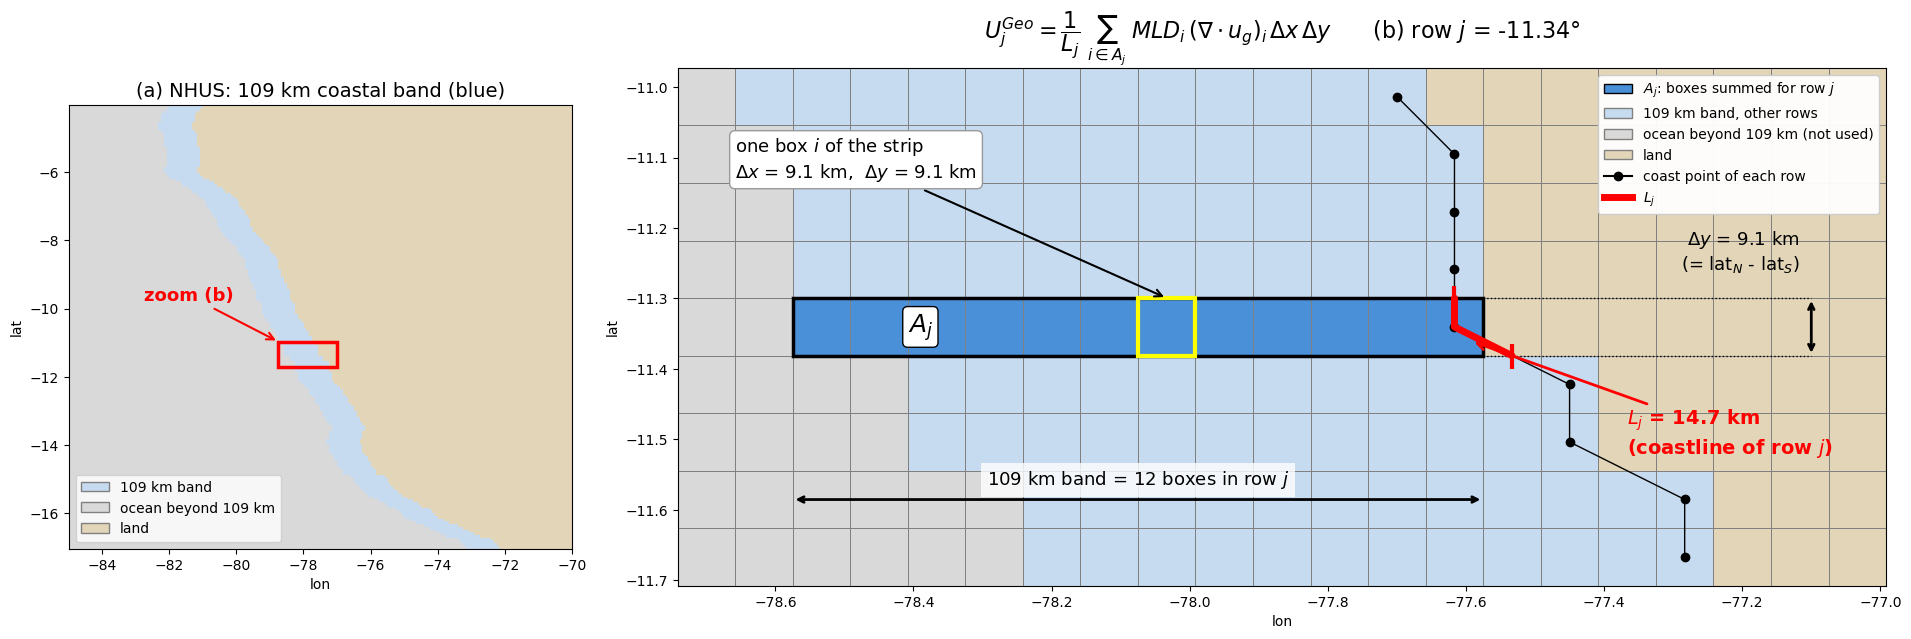

row -11.34:  12 boxes,  dy = 9.1 km,  L_j = 14.7 km,  dy/L_j = 0.62


In [56]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle, Patch
from matplotlib.lines import Line2D

lat_r = ds_row.sel(**rows).lat.values
L_r   = ds_row.sel(**rows).values                       # m
c_lon = coast_lons.sel(**rows).values
dlon  = np.abs(float(eta.lon[1] - eta.lon[0]))

# example row: between 13S and 10S, the one where the coast steps sideways the most
cand = np.where((lat_r >= -13) & (lat_r <= -10))[0][1:-1]
k    = cand[np.nanargmax(L_r[cand])]
lat_k, lon_k = lat_r[k], c_lon[k]
jj   = int(np.argmin(np.abs(lat_all - lat_k)))
dlat = 0.5 * (lat_all[jj + 1] - lat_all[jj - 1])
dy   = DEG2M * dlat
dx   = DEG2M * np.cos(np.deg2rad(lat_k)) * dlon

strip   = mask_band.isel(lat=jj)
lon_off = float(strip.lon.where(strip, drop=True).min())   # offshore edge of the strip
n_box   = int(strip.sum())

# box categories: 0 ocean outside band, 1 band (other rows), 2 strip A_j, 3 land
cat = xr.where(~ocean, 3, xr.where(mask_band, 1, 0))
cat[dict(lat=jj)] = xr.where(strip, 2, cat.isel(lat=jj))
win = dict(lat=slice(lat_all[jj - 4] - 1e-6, lat_all[jj + 4] + 1e-6),
           lon=slice(lon_off - 2.5 * dlon, lon_k + 7.5 * dlon))
cw  = cat.sel(**win)
cmap4 = ListedColormap(['#d9d9d9', '#c6dbef', '#4a90d9', '#e3d5b8'])  # ocean beyond band, band, A_j, land

fig, (axm, ax) = plt.subplots(1, 2, figsize=(19, 8), constrained_layout=True,
                              gridspec_kw={'width_ratios': [1, 2.4]})

# (a) map of the whole NHUS band, with the zoom box
cm = cat.where(cat != 2, 1).sel(lat=slice(lati2, lati1), lon=slice(-85, -70))
axm.pcolormesh(cm.lon, cm.lat, cm, shading='nearest', vmin=-0.5, vmax=3.5, cmap=cmap4)
x0, x1 = float(cw.lon.min()) - dlon / 2, float(cw.lon.max()) + dlon / 2
y0, y1 = float(cw.lat.min()) - dlat / 2, float(cw.lat.max()) + dlat / 2
axm.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='red', lw=2.5, zorder=3))
axm.annotate('zoom (b)', xy=(x0, y1), xytext=(x0 - 4, y1 + 1.2), color='red', fontsize=13, fontweight='bold',
             arrowprops=dict(arrowstyle='->', color='red', lw=1.5))
axm.set_aspect(1 / np.cos(np.deg2rad(-10.5)))
axm.set_xlabel('lon'); axm.set_ylabel('lat')
axm.set_title(f'(a) NHUS: {mask_km} km coastal band (blue)', fontsize=14)
axm.legend(handles=[Patch(fc='#c6dbef', ec='0.5', label=f'{mask_km} km band'),
                    Patch(fc='#d9d9d9', ec='0.5', label=f'ocean beyond {mask_km} km'),
                    Patch(fc='#e3d5b8', ec='0.5', label='land')], loc='lower left', fontsize=10)
ax.pcolormesh(cw.lon, cw.lat, cw, shading='nearest', vmin=-0.5, vmax=3.5,
              cmap=cmap4,
              edgecolors='0.5', linewidth=0.5)
ax.add_patch(Rectangle((lon_off - dlon / 2, lat_k - dlat / 2), lon_k - lon_off + dlon, dlat,
                       fill=False, ec='k', lw=2.5, zorder=3))
ax.text(lon_off + 1.5 * dlon, lat_k, '$A_j$', fontsize=18, fontweight='bold', va='center', zorder=4,
        bbox=dict(fc='white', ec='k', boxstyle='round,pad=0.2'))

# coast point of each row + the piece of coast that belongs to row j
w = (lat_r >= cw.lat.min().item()) & (lat_r <= cw.lat.max().item())
ax.plot(c_lon[w], lat_r[w], 'o-', color='k', ms=6, lw=1, zorder=4)
mid_s = (0.5 * (c_lon[k - 1] + lon_k), 0.5 * (lat_r[k - 1] + lat_k))
mid_n = (0.5 * (c_lon[k + 1] + lon_k), 0.5 * (lat_r[k + 1] + lat_k))
ax.plot([mid_s[0], lon_k, mid_n[0]], [mid_s[1], lat_k, mid_n[1]], color='red', lw=5, zorder=5,
        solid_capstyle='round')
for p in (mid_s, mid_n):
    ax.plot(*p, marker='|', color='red', ms=18, mew=3, zorder=5)
ax.annotate(f'$L_j$ = {L_r[k] / 1e3:.1f} km\n(coastline of row $j$)', xy=(lon_k + 0.3 * dlon, lat_k - 0.25 * dlat),
            xytext=(lon_k + 3.0 * dlon, lat_k - 2.2 * dlat), color='red', fontsize=14, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='red', lw=2), zorder=6)

# Delta y of the row
xb = lon_k + 6.2 * dlon
ax.annotate('', xy=(xb, lat_k - dlat / 2), xytext=(xb, lat_k + dlat / 2),
            arrowprops=dict(arrowstyle='<->', color='k', lw=2))
ax.plot([lon_k + dlon / 2, xb], [lat_k + dlat / 2] * 2, 'k:', lw=1)
ax.plot([lon_k + dlon / 2, xb], [lat_k - dlat / 2] * 2, 'k:', lw=1)
ax.text(xb - 0.2 * dlon, lat_k + 1.0 * dlat, f'$\\Delta y$ = {dy / 1e3:.1f} km\n(= lat$_N$ - lat$_S$)',
        ha='right', fontsize=13)

# one box of the sum
ib = lon_off + 6 * dlon
ax.add_patch(Rectangle((ib - dlon / 2, lat_k - dlat / 2), dlon, dlat, fill=False, ec='yellow', lw=3, zorder=4))
ax.annotate('one box $i$ of the strip'
            f'\n$\\Delta x$ = {dx / 1e3:.1f} km,  $\\Delta y$ = {dy / 1e3:.1f} km',
            xy=(ib, lat_k + dlat / 2), xytext=(lon_off - 1.5 * dlon, lat_k + 2.6 * dlat), fontsize=13,
            arrowprops=dict(arrowstyle='->', color='k', lw=1.5), zorder=6,
            bbox=dict(fc='white', ec='0.6', boxstyle='round'))

# band width
yb = lat_k - 3 * dlat
ax.annotate('', xy=(lon_off - dlon / 2, yb), xytext=(lon_k + dlon / 2, yb),
            arrowprops=dict(arrowstyle='<->', color='k', lw=2))
ax.text(0.5 * (lon_off + lon_k), yb + 0.15 * dlat, f'{mask_km} km band = {n_box} boxes in row $j$',
        ha='center', va='bottom', fontsize=13, bbox=dict(fc='white', ec='none', alpha=0.8))

ax.set_title('$U^{Geo}_j = \\dfrac{1}{L_j}\\;\\sum_{i\\in A_j}\\;MLD_i\\,(\\nabla\\cdot u_g)_i\\,\\Delta x\\,\\Delta y$'
             f'      (b) row $j$ = {lat_k:.2f}°',
             fontsize=16, pad=12)
ax.set_aspect(1 / np.cos(np.deg2rad(lat_k)))
ax.set_xlim(float(cw.lon.min()) - dlon / 2, float(cw.lon.max()) + dlon / 2)
ax.set_ylim(float(cw.lat.min()) - dlat / 2, float(cw.lat.max()) + dlat / 2)
ax.set_xlabel('lon'); ax.set_ylabel('lat')
ax.legend(handles=[Patch(fc='#4a90d9', ec='k', label='$A_j$: boxes summed for row $j$'),
                   Patch(fc='#c6dbef', ec='0.5', label=f'{mask_km} km band, other rows'),
                   Patch(fc='#d9d9d9', ec='0.5', label=f'ocean beyond {mask_km} km (not used)'),
                   Patch(fc='#e3d5b8', ec='0.5', label='land'),
                   Line2D([], [], color='k', marker='o', label='coast point of each row'),
                   Line2D([], [], color='red', lw=5, label='$L_j$')],
          loc='upper right', fontsize=10, framealpha=0.95)
plt.show()

print(f'row {lat_k:.2f}:  {n_box} boxes,  dy = {dy/1e3:.1f} km,  L_j = {L_r[k]/1e3:.1f} km,  dy/L_j = {dy / L_r[k]:.2f}')

## 4. $U^{Ek}$ from the ERA5 forcing winds on the native C-grid

* `uwnd` sits on the u-faces (index `i` = east face of cell `i`), `vwnd` on the v-faces (index `j` = north face of row `j`).
* At each face: native component + 4-point mean of the other one, $\tau=\rho_a C_d|\mathbf U|\mathbf U$ from monthly-mean winds (as in the paper), $U_{ek}=\tau_y/(\rho_0 f)$ on east faces, $V_{ek}=-\tau_x/(\rho_0 f)$ on north faces, $f$ at the face latitude.
* Closed faces carry no flux; no MLD factor (Ekman transport is depth-integrated).

In [57]:
def ekman_faces_from_forcing(years=YEARS):
    """Ekman volume fluxes (m3/s) through the EAST and NORTH face of every cell of the reg2d sub-grid, one per month."""
    lat_f = mld_all.lat.values
    j = np.where((lat_f >= lat_all[0] - 1e-9) & (lat_f <= lat_all[-1] + 1e-9))[0]
    lon_f = mld_all.lon.values
    i = np.where((lon_f >= eta.lon.values[0] - 1e-9) & (lon_f <= eta.lon.values[-1] + 1e-9))[0]
    j0, j1, i0, i1 = j[0], j[-1] + 1, i[0], i[-1] + 1
    ny, nx = len(lat_f), len(lon_f)
    f_e = 2 * OMEGA_EK * np.sin(np.deg2rad(lat_all))[:, None]                 # east faces: row latitude
    f_n = 2 * OMEGA_EK * np.sin(np.deg2rad(lat_n.values))[:, None]            # north faces: mid latitude
    ke, kn = (open_e * dy_e).fillna(0.0).values, (open_n * dx_n).fillna(0.0).values
    Fe, Fn = [], []
    for y in years:
        for m in range(1, 13):
            with xr.open_dataset(WIND_FILES.format(y=y, m=m), decode_times=False) as ds:
                u = ds.uwnd.isel(bulk_time=0).values.astype('float64')       # (ny, nx-1): east face of cell i
                v = ds.vwnd.isel(bulk_time=0).values.astype('float64')       # (ny-1, nx): north face of row j
            U = np.full((ny, nx), np.nan); U[:, :-1] = u                    # U[j, i] = east face of cell (j, i)
            V = np.full((ny, nx), np.nan); V[:-1, :] = v                    # V[j, i] = north face of cell (j, i)
            Vp = np.pad(V, 1, constant_values=np.nan); Up = np.pad(U, 1, constant_values=np.nan)
            # v at the east face of (j, i): north faces of (j-1, i), (j-1, i+1), (j, i), (j, i+1)
            v_e = 0.25 * (Vp[0:-2, 1:-1] + Vp[0:-2, 2:] + Vp[1:-1, 1:-1] + Vp[1:-1, 2:])
            # u at the north face of (j, i): east faces of (j, i-1), (j, i), (j+1, i-1), (j+1, i)
            u_n = 0.25 * (Up[1:-1, 0:-2] + Up[1:-1, 1:-1] + Up[2:, 0:-2] + Up[2:, 1:-1])
            sl = (slice(j0, j1), slice(i0, i1))
            ue, ve, un, vn = U[sl], v_e[sl], u_n[sl], V[sl]
            tauy_e = RHO_AIR * CD * np.hypot(ue, ve) * ve
            taux_n = RHO_AIR * CD * np.hypot(un, vn) * un
            Fe.append(np.nan_to_num(tauy_e / (RHO_SW * f_e)) * ke)
            Fn.append(np.nan_to_num(-taux_n / (RHO_SW * f_n)) * kn)
    mk = lambda a: xr.DataArray(np.stack(a), dims=('time', 'lat', 'lon'),
                                coords={'time': eta.time, 'lat': eta.lat, 'lon': eta.lon})
    return mk(Fe).rename('Fe_ek'), mk(Fn).rename('Fn_ek')


Fe_ek, Fn_ek = ekman_faces_from_forcing()

# Ekman divergence of each row's strip, m3/s
I_ek_row = fv_divergence(Fe_ek, Fn_ek).where(mask_band).sum('lon').sel(**rows)

## 5. CROCO $W_{MLD}$ and the CUTI at every resolution

$\iint W\,dA$ uses the same boxes and the same cell areas ($1/(pm\,pn)$) as the CUTI, and both are divided by the same $L$. Bins: transports (m³/s) are summed over the rows of a bin and divided by the summed $L$.

In [58]:
wmld    = xr.open_dataset('W_mld_Croco.nc').sel(**reg2d).compute().astype('float64')
assert np.array_equal(wmld.lat.values, lat_all) and np.array_equal(wmld.lon.values, eta.lon.values)
I_W_row = ((wmld.WMLD * dA).where(mask_band).sum('lon', min_count=1)
           .reindex(lat=row_lats, method='nearest', tolerance=0.02))            # m3/s
del wmld

ds_ok = ds_row.sel(**rows).where(np.isfinite(ds_row.sel(**rows)))             # L per row, m
valid = ds_ok.notnull()


def cuti_at(dbin):
    # U_ek, U_geo, CUTI and CROCO W per metre of coast, aggregated to bins of width dbin (None = per row), m2/s
    L   = bin_rows(ds_ok, dbin)
    per = lambda I: (bin_rows(I.where(valid), dbin) / L).sortby('lat_band')
    out = dict(U_ek=per(I_ek_row), U_geo=per(I_geo_row), W=per(I_W_row))
    out['CUTI'] = out['U_ek'] + out['U_geo']
    return out


res = {name: cuti_at(d) for name, d in resolutions.items()}
for name, r in res.items():
    m = {k: float(coast_mean(v.sel(**bs), resolutions[name]).mean()) for k, v in r.items()}
    print(f"{name:12s} bins: {r['CUTI'].sizes['lat_band']:4d}   5-16S mean [m2/s]:  U_ek {m['U_ek']:+.3f}   "
          f"U_geo {m['U_geo']:+.3f}   CUTI {m['CUTI']:+.3f}   CROCO W {m['W']:+.3f}")

row (1/12°)  bins:  159   5-16S mean [m2/s]:  U_ek +2.087   U_geo -0.338   CUTI +1.748   CROCO W +1.433
0.25°        bins:   52   5-16S mean [m2/s]:  U_ek +2.087   U_geo -0.338   CUTI +1.748   CROCO W +1.433
0.5°         bins:   26   5-16S mean [m2/s]:  U_ek +2.087   U_geo -0.338   CUTI +1.748   CROCO W +1.433
1°           bins:   13   5-16S mean [m2/s]:  U_ek +2.087   U_geo -0.338   CUTI +1.748   CROCO W +1.433


## 6. Skill: CUTI vs CROCO

r(time) per bin (Fisher-z mean, raw and with the monthly climatology removed), effective sample size (Bretherton et al. 1999), 95 % bootstrap intervals (whole years for r(time), ~1° latitude blocks for r(profile)); bias, ratio and the 5–16°S correlations use the region value $(1/L)\iint$.

In [59]:
def skill_row(C, W, dbin=None):
    C, W = C.sel(**bs), W.sel(**bs)
    Cp, Wp = C.mean('time'), W.mean('time')
    cs, ws = coast_mean(C, dbin), coast_mean(W, dbin)          # 5-16S series, Eq. 2.7 (L-weighted)
    rt  = xr.corr(C, W, dim='time')
    Ca, Wa = anomalies(C), anomalies(W)
    rta = xr.corr(Ca, Wa, dim='time')
    years = C.time.dt.year.values
    ci  = boot_time(C, W, years)
    cia = boot_time(Ca, Wa, years)
    neff_t = float(np.median([n_eff(Ca.isel(lat_band=k), Wa.isel(lat_band=k), 'time') for k in range(C.sizes['lat_band'])]))
    block = int(round(1.0 / dbin)) if dbin else 12                              # ~1 degree blocks along the profile
    cip = boot_profile(Cp, Wp, block)
    return {'r(time) mean': float(rt.mean()),
            'r(time) Fisher': fisher_mean(rt.values),
            'r(time) CI95': f'{ci[0]:.2f}-{ci[1]:.2f}',
            'r(time) anom': fisher_mean(rta.values),
            'r(time) anom CI95': f'{cia[0]:.2f}-{cia[1]:.2f}',
            'n_eff(time)': neff_t,
            'r(profile)': float(xr.corr(Cp, Wp)),
            'r(profile) CI95': f'{cip[0]:.2f}-{cip[1]:.2f}',
            'n_eff(profile)': n_eff(Cp, Wp, 'lat_band'),
            'RMSE prof': float(np.sqrt(((Cp - Wp) ** 2).mean())),
            'bias': float((cs - ws).mean()),
            'CUTI/CROCO (mean)': float(cs.mean() / ws.mean()),
            'r(5-16S)': float(xr.corr(cs, ws)),
            'r(5-16S) anom': float(xr.corr(anomalies(cs), anomalies(ws))),
            'r seas.': float(xr.corr(seasonality(cs), seasonality(ws)))}

tab = pd.DataFrame({name: skill_row(r['CUTI'], r['W'], resolutions[name]) for name, r in res.items()}).T
tab.index.name = 'resolution'
tab.round(3)

,r(time) mean,r(time) Fisher,r(time) CI95,r(time) anom,r(time) anom CI95,n_eff(time),r(profile),r(profile) CI95,n_eff(profile),RMSE prof,bias,CUTI/CROCO (mean),r(5-16S),r(5-16S) anom,r seas.
resolution,,,,,,,,,,,,,,,
row (1/12°),0.338192,0.369212,0.34-0.40,0.213283,0.18-0.24,381.490847,0.3816,0.06-0.53,96.307798,0.907199,0.315315,1.220039,0.915039,0.820207,0.992571
0.25°,0.39804,0.434347,0.40-0.46,0.264679,0.23-0.29,371.924781,0.630137,0.07-0.79,31.387675,0.595113,0.315315,1.220039,0.915039,0.820207,0.992571
0.5°,0.511395,0.542403,0.51-0.57,0.362436,0.33-0.39,354.94037,0.674566,0.02-0.84,21.134559,0.534579,0.315315,1.220039,0.915039,0.820207,0.992571
1°,0.687177,0.695769,0.67-0.72,0.521535,0.49-0.55,321.740001,0.566218,0.12-0.85,11.538744,0.482027,0.315315,1.220039,0.915039,0.820207,0.992571


## 7. Time-mean profiles

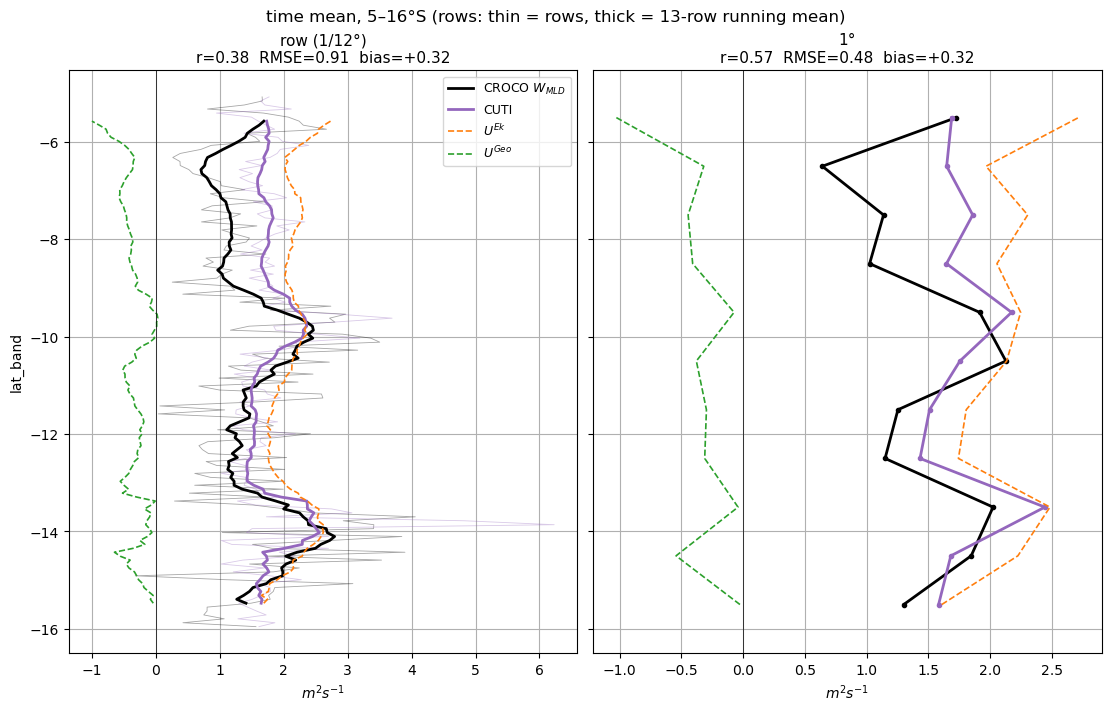

In [60]:
fig, ax = plt.subplots(1, 2, figsize=(11, 7), sharey=True, constrained_layout=True)
for a, name in zip(ax, ['row (1/12°)', '1°']):
    r  = {k: v.sel(**bs).mean('time') for k, v in res[name].items()}
    mk = '.' if name == '1°' else None
    if name.startswith('row'):
        r['W'].plot(y='lat_band', ax=a, color='k', lw=0.6, alpha=0.35)
        r['CUTI'].plot(y='lat_band', ax=a, color='tab:purple', lw=0.6, alpha=0.35)
        r = {k: v.rolling(lat_band=13, center=True).mean() for k, v in r.items()}
    r['W'].plot(y='lat_band', ax=a, color='k', lw=2, marker=mk, label='CROCO $W_{MLD}$')
    r['CUTI'].plot(y='lat_band', ax=a, color='tab:purple', lw=2, marker=mk, label='CUTI')
    r['U_ek'].plot(y='lat_band', ax=a, color='tab:orange', lw=1.2, ls='--', label='$U^{Ek}$')
    r['U_geo'].plot(y='lat_band', ax=a, color='tab:green', lw=1.2, ls='--', label='$U^{Geo}$')
    s = tab.loc[name]
    a.set_title(f'{name}\nr={s["r(profile)"]:.2f}  RMSE={s["RMSE prof"]:.2f}  bias={s["bias"]:+.2f}', fontsize=11)
    a.axvline(0, color='k', lw=0.5); a.set_xlabel('$m^2 s^{-1}$'); a.grid(True)
ax[1].set_ylabel(''); ax[0].legend(fontsize=9)
fig.suptitle('time mean, 5–16°S (rows: thin = rows, thick = 13-row running mean)')
plt.show()

## 8. Seasonal cycle and interannual variability, 5–16°S

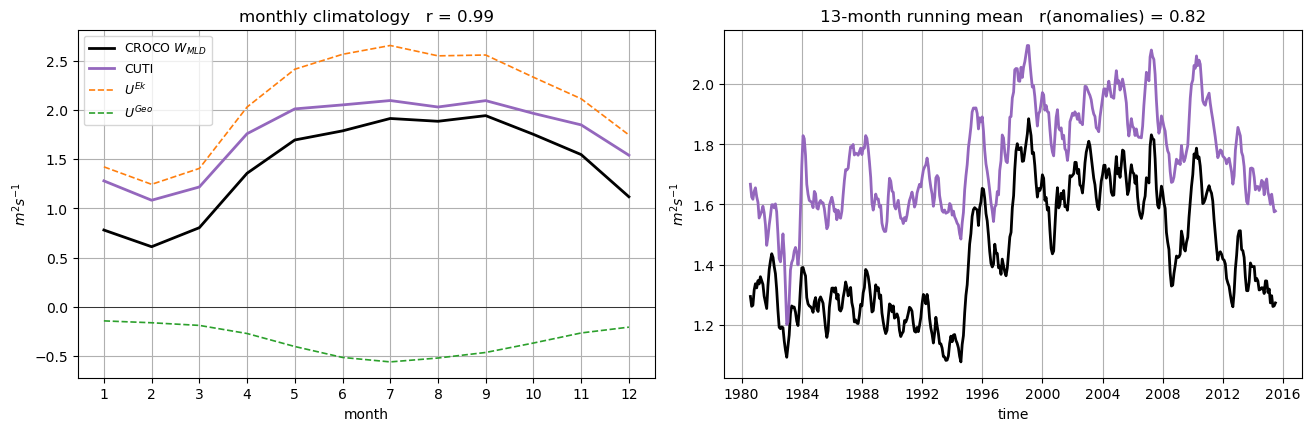

In [61]:
r = {k: coast_mean(v.sel(**bs)) for k, v in res['row (1/12°)'].items()}        # 5-16S, (1/L) iint
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)
for k, c, ls, lab in [('W', 'k', '-', 'CROCO $W_{MLD}$'), ('CUTI', 'tab:purple', '-', 'CUTI'),
                      ('U_ek', 'tab:orange', '--', '$U^{Ek}$'), ('U_geo', 'tab:green', '--', '$U^{Geo}$')]:
    seasonality(r[k]).plot(ax=ax[0], color=c, ls=ls, lw=2 if ls == '-' else 1.2, label=lab)
for k, c in [('W', 'k'), ('CUTI', 'tab:purple')]:
    r[k].rolling(time=13, center=True).mean().plot(ax=ax[1], color=c, lw=2)
ax[0].set_xticks(range(1, 13)); ax[0].axhline(0, color='k', lw=0.5)
ax[0].set_title(f"monthly climatology   r = {float(xr.corr(seasonality(r['CUTI']), seasonality(r['W']))):.2f}")
ax[1].set_title(f"13-month running mean   r(anomalies) = {float(xr.corr(anomalies(r['CUTI']), anomalies(r['W']))):.2f}")
for a in ax:
    a.set_ylabel('$m^2 s^{-1}$'); a.grid(True)
ax[0].legend(fontsize=9)
plt.show()

## 9. Save: `CUTI_BEUTI_HR_L_v4.nc`

One `lat_band` per grid row (N → S), per metre of coastline: `CUTI` = `U_ek` + `UGEO`, `BEUTI` = `N_mld` × `CUTI`, `W_L` = CROCO $\iint W\,dA/L$, `L_coast` = coast length of the row (m).

In [64]:
coast_cell = mask_band & ~mask_band.shift(lon=-1, fill_value=False)
nitrogen = xr.open_dataset('Nitrogen.nc').sel(**reg2d)[['TN_mld']].compute()
rows_ = lambda da: da.reindex(lat=row_lats, method='nearest', tolerance=0.02).rename(lat='lat_band')
N_row = rows_(nitrogen.TN_mld.where(coast_cell).mean('lon'))
del nitrogen

r0 = res['row (1/12°)']
dy_row = (1.0 / pn).mean('lon').sel(**rows).where(valid)                        # row height, m (Mercator: varies with latitude)
out_L = xr.Dataset({
    'CUTI'   : r0['CUTI'],
    'U_ek'   : r0['U_ek'],
    'UGEO'   : r0['U_geo'],
    'BEUTI'  : N_row * r0['CUTI'],
    'N_mld'  : N_row,
    'W_L'    : r0['W'],                   # CROCO reference
    'L_coast': rows_(ds_ok),
    'dy'     : rows_(dy_row),
})
out_L = (out_L.drop_vars([v for v in out_L.coords if v not in ('time', 'lat_band')])
              .sortby('lat_band', ascending=False).transpose('lat_band', ...))
out_L = out_L.assign_coords(year=out_L.time.dt.year, month=out_L.time.dt.month)

attrs = {
    'CUTI'   : ('m2/s', 'U_ek + UGEO, per metre of coastline'),
    'U_ek'   : ('m2/s', 'Ekman divergence integrated over the row strip / L_coast; ERA5 forcing winds on the native C-grid'),
    'UGEO'   : ('m2/s', 'Eq. 2.7: integral of MLD * div(u_g) over the closed row strip / L_coast'),
    'BEUTI'  : ('N x m2/s', 'N_mld x CUTI'),
    'N_mld'  : ('as Nitrogen.nc TN_mld', 'TN_mld at the coast box of each row'),
    'W_L'    : ('m2/s', 'CROCO W_MLD integrated over the same row strip (area 1/(pm pn)) / L_coast'),
    'L_coast': ('m', 'along-coast length of the row: half the distance to each neighbouring coast box'),
    'dy'     : ('m', 'row height used in the area integrals (1/pn, varies with latitude on the Mercator grid)'),
}
for v, (u, d) in attrs.items():
    out_L[v].attrs = {'units': u, 'description': d}
out_L.lat_band.attrs = {'long_name': 'grid-row latitude (1/12 deg Mercator, no binning)', 'units': 'degrees_north'}
out_L.attrs.update({
    'method'     : f'CUTI_v4: band = round({mask_km} km / dx) boxes incl. the coast box; per metre of coastline; '
                   'regional values = total transport / total coast length',
    'wind_source': WIND_FILES.replace('{y}M{m}', '{1980..2015}M{1..12}') + ' (uwnd on u-faces, vwnd on v-faces, monthly means)',
    'ekman'      : f'tau = {RHO_AIR}*{CD}*|U|U at each face (native component + 4-point mean of the other); '
                   f'U_ek = tau_y/({RHO_SW} f), V_ek = -tau_x/({RHO_SW} f), f = 2*{OMEGA_EK}*sin(face latitude)',
    'geostrophy' : 'u_g = -(g/f) dSSH/dy, v_g = (g/f) dSSH/dx (centred, 0 across a land neighbour); UGEO = sum MLD * div(u_g) * area',
    'closure'    : 'zero flux through every ocean-land face (E/W and N/S), Ekman and geostrophic',
    'metrics'    : 'CROCO pm, pn (Mercator grid): area 1/(pm pn), east face 2/(pn_i+pn_i+1), north face 2/(pm_j+pm_j+1)',
})
print(out_L)
out_L.to_netcdf('CUTI_BEUTI_HR_L_C.nc')

<xarray.Dataset> Size: 3MB
Dimensions:   (time: 432, lat_band: 159)
Coordinates:
  * time      (time) datetime64[ns] 3kB 1980-01-31 1980-02-29 ... 2015-12-31
  * lat_band  (lat_band) float64 1kB -4.079 -4.162 -4.245 ... -16.91 -16.99
    year      (time) int64 3kB 1980 1980 1980 1980 1980 ... 2015 2015 2015 2015
    month     (time) int64 3kB 1 2 3 4 5 6 7 8 9 10 ... 3 4 5 6 7 8 9 10 11 12
Data variables:
    CUTI      (lat_band, time) float64 550kB 5.652 4.286 2.605 ... 0.7444 0.5402
    U_ek      (lat_band, time) float64 550kB 8.718 5.83 3.278 ... 0.4995 0.4417
    UGEO      (lat_band, time) float64 550kB -3.066 -1.543 ... 0.245 0.09843
    BEUTI     (lat_band, time) float64 550kB 35.63 17.21 9.455 ... 4.585 1.268
    N_mld     (lat_band, time) float64 550kB 6.304 4.014 3.629 ... 6.159 2.347
    W_L       (lat_band, time) float64 550kB 2.463 1.486 ... 0.3086 -0.4332
    L_coast   (lat_band) float64 1kB 1.116e+04 1.307e+04 ... 1.254e+04 1.617e+04
    dy        (lat_band) float64 1kB 9